# **Predictive Modeling and Optimization in Logistics Systems**


### **Load and Validate the Dataset**

Load the cleaned logistics dataset prepared during the previous weeks and verify its dimensions, column names, data types, missing values, duplicate records, and target variable before developing the predictive model.




In [2]:

import pandas as pd
import numpy as np

# Load the cleaned dataset from Week 3
file_path = "/content/cleaned_logistics_dataset (1).csv"
df = pd.read_csv(file_path)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

target = "Time_taken(min)"
print("\nTarget variable available:", target in df.columns)

if target in df.columns:
    print("\nTarget variable summary:")
    print(df[target].describe())


Dataset loaded successfully.
Dataset shape: (45593, 20)

Column names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Data types:
ID                              object
Delivery_person_ID              object
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weatherconditions               object
Road_traffic_density            object
Vehicle_


### **Identify the Target Variable**

The target variable `Time_taken(min)` is selected to predict food delivery time in minutes using the available logistics features.


In [3]:

# Define the target variable and input features

target = "Time_taken(min)"

X = df.drop(columns=[target, "ID", "Delivery_person_ID"])
y = df[target]

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)
print("\nTarget variable: ", target)
print("\nInput features:")
print(X.columns.tolist())


Input features shape: (45593, 17)
Target variable shape: (45593,)

Target variable:  Time_taken(min)

Input features:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City']



### **Separate Numerical and Categorical Features**

The input features are separated into numerical and categorical columns to prepare the dataset for preprocessing and model training.


In [4]:
# Separate numerical and categorical features

numerical_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object"]).columns.tolist()

print("Numerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))


Numerical features: ['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Vehicle_condition', 'multiple_deliveries']

Number of numerical features: 8

Categorical features: ['Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']

Number of categorical features: 9



### **Prepare Features for Model Training**

The numerical and categorical features are prepared for preprocessing. Date and time columns are converted into suitable formats, and categorical variables are encoded before training the predictive model.


In [5]:
# Create a copy of the input features
X_processed = X.copy()

# Convert date column to datetime
X_processed["Order_Date"] = pd.to_datetime(
    X_processed["Order_Date"], errors="coerce", dayfirst=True
)

# Extract useful date components
X_processed["Order_Day"] = X_processed["Order_Date"].dt.day
X_processed["Order_Month"] = X_processed["Order_Date"].dt.month
X_processed["Order_Weekday"] = X_processed["Order_Date"].dt.dayofweek

# Remove the original date column
X_processed.drop(columns=["Order_Date"], inplace=True)

# Convert time columns into minutes after midnight
def convert_time_to_minutes(value):
    try:
        if pd.isna(value) or str(value).strip() in ["", "NaN", "nan"]:
            return np.nan

        value = str(value).strip()
        parsed_time = pd.to_datetime(value, format="%H:%M", errors="coerce")

        if pd.isna(parsed_time):
            return np.nan

        return parsed_time.hour * 60 + parsed_time.minute

    except (ValueError, TypeError):
        return np.nan

for col in ["Time_Orderd", "Time_Order_picked"]:
    X_processed[col] = X_processed[col].apply(convert_time_to_minutes)

# Display the processed features
print("Processed dataset shape:", X_processed.shape)
print("\nProcessed data types:")
print(X_processed.dtypes)
print("\nMissing values after conversion:")
print(X_processed.isnull().sum())


/tmp/ipykernel_1371/2882609078.py:5: UserWarning: Parsing dates in %Y-%m-%d format when dayfirst=True was specified. Pass `dayfirst=False` or specify a format to silence this warning.
  X_processed["Order_Date"] = pd.to_datetime(


Processed dataset shape: (45593, 19)

Processed data types:
Delivery_person_Age            float64
Delivery_person_Ratings        float64
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Time_Orderd                    float64
Time_Order_picked              float64
Weatherconditions               object
Road_traffic_density            object
Vehicle_condition                int64
Type_of_order                   object
Type_of_vehicle                 object
multiple_deliveries            float64
Festival                        object
City                            object
Order_Day                        int32
Order_Month                      int32
Order_Weekday                    int32
dtype: object

Missing values after conversion:
Delivery_person_Age                0
Delivery_person_Ratings            0
Restaurant_latitude                0
Restaurant_longitude               0
Del


### **Correct Time Feature Conversion**

The order and pickup time columns are converted into minutes after midnight by extracting their hour and minute components. Missing values are checked to ensure the features are suitable for preprocessing.


In [7]:

# Convert order and pickup times into minutes after midnight

for col in ["Time_Orderd", "Time_Order_picked"]:
    parsed_time = pd.to_datetime(X[col], errors="coerce")
    X_processed[col] = (
        parsed_time.dt.hour * 60 + parsed_time.dt.minute
    )

print("Missing values in time columns:")
print(X_processed[["Time_Orderd", "Time_Order_picked"]].isnull().sum())

print("\nSample converted time values:")
print(X_processed[["Time_Orderd", "Time_Order_picked"]].head(10))

print("\nProcessed dataset shape:", X_processed.shape)


Missing values in time columns:
Time_Orderd          0
Time_Order_picked    0
dtype: int64

Sample converted time values:
   Time_Orderd  Time_Order_picked
0          690                705
1         1185               1190
2          510                525
3         1080               1090
4          810                825
5         1280               1290
6         1155               1170
7         1045               1050
8         1255               1265
9         1315               1330

Processed dataset shape: (45593, 19)



### **Encode Categorical Features**

Categorical features are converted into numerical representations using one-hot encoding so they can be used by machine learning algorithms. The target variable remains unchanged for regression model training.


In [8]:

# Identify categorical columns
categorical_cols = X_processed.select_dtypes(
    include=["object"]
).columns.tolist()

print("Categorical columns:", categorical_cols)

# Apply one-hot encoding
X_encoded = pd.get_dummies(
    X_processed,
    columns=categorical_cols,
    drop_first=True,
    dtype=int
)

print("\nShape before encoding:", X_processed.shape)
print("Shape after encoding:", X_encoded.shape)

print("\nEncoded feature sample:")
print(X_encoded.head())


Categorical columns: ['Weatherconditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']

Shape before encoding: (45593, 19)
Shape after encoding: (45593, 34)

Encoded feature sample:
   Delivery_person_Age  Delivery_person_Ratings  Restaurant_latitude  \
0                 37.0                      4.9            22.745049   
1                 34.0                      4.5            12.913041   
2                 23.0                      4.4            12.914264   
3                 38.0                      4.7            11.003669   
4                 32.0                      4.6            12.972793   

   Restaurant_longitude  Delivery_location_latitude  \
0             75.892471                   22.765049   
1             77.683237                   13.043041   
2             77.678400                   12.924264   
3             76.976494                   11.053669   
4             80.249982                   13.012793   

   Delivery_locati


### **Split the Dataset into Training and Testing Sets**

The encoded dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to build the predictive model, while the testing set is used to evaluate its performance on unseen data.


In [9]:

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (36474, 34)
Testing features shape: (9119, 34)
Training target shape: (36474,)
Testing target shape: (9119,)



### **Train the Linear Regression Model**

A Linear Regression model is trained using the training dataset to establish a baseline for predicting food delivery time. The model learns the relationship between the input features and the target variable.


In [10]:

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train, y_train)

# Generate predictions on the test set
y_pred_linear = linear_model.predict(X_test)

print("Linear Regression model trained successfully.")
print("Number of training records:", X_train.shape[0])
print("Number of testing records:", X_test.shape[0])
print("\nSample actual delivery times:", y_test.iloc[:10].tolist())
print("Sample predicted delivery times:", np.round(y_pred_linear[:10], 2).tolist())


Linear Regression model trained successfully.
Number of training records: 36474
Number of testing records: 9119

Sample actual delivery times: [44, 41, 39, 38, 38, 22, 14, 17, 22, 29]
Sample predicted delivery times: [37.75, 34.72, 34.77, 35.37, 32.78, 24.17, 20.07, 21.58, 22.44, 29.44]



### **Evaluate the Linear Regression Model**

The Linear Regression model is evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and the coefficient of determination (R²) to measure prediction accuracy and model performance.


In [11]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate regression evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mse_linear)
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Model Performance")
print("-----------------------------------")
print(f"Mean Absolute Error (MAE): {mae_linear:.2f} minutes")
print(f"Mean Squared Error (MSE): {mse_linear:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_linear:.2f} minutes")
print(f"R-squared (R²): {r2_linear:.4f}")


Linear Regression Model Performance
-----------------------------------
Mean Absolute Error (MAE): 4.88 minutes
Mean Squared Error (MSE): 38.22
Root Mean Squared Error (RMSE): 6.18 minutes
R-squared (R²): 0.5641



### **Train the Random Forest Regression Model**

A Random Forest Regressor is trained to capture complex relationships between logistics features and delivery time. Its performance is compared with the Linear Regression baseline to identify a more effective predictive model.


In [12]:

from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Regression model trained successfully.")
print("\nSample actual delivery times:", y_test.iloc[:10].tolist())
print("Sample predicted delivery times:", np.round(y_pred_rf[:10], 2).tolist())


Random Forest Regression model trained successfully.

Sample actual delivery times: [44, 41, 39, 38, 38, 22, 14, 17, 22, 29]
Sample predicted delivery times: [44.44, 42.12, 35.62, 41.64, 29.52, 21.96, 14.56, 23.55, 22.4, 26.53]



### **Evaluate the Random Forest Regression Model**

The Random Forest model is evaluated using MAE, MSE, RMSE, and R². These metrics measure prediction errors and explain how well the model estimates food delivery time on unseen data.


In [13]:

# Evaluate Random Forest Regression
mae_rf = mean_absolute_error(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Regression Model Performance")
print("-------------------------------------------")
print(f"Mean Absolute Error (MAE): {mae_rf:.2f} minutes")
print(f"Mean Squared Error (MSE): {mse_rf:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse_rf:.2f} minutes")
print(f"R-squared (R²): {r2_rf:.4f}")


Random Forest Regression Model Performance
-------------------------------------------
Mean Absolute Error (MAE): 3.72 minutes
Mean Squared Error (MSE): 22.61
Root Mean Squared Error (RMSE): 4.76 minutes
R-squared (R²): 0.7421



### **Compare Model Performance**

The Linear Regression and Random Forest models are compared using MAE, MSE, RMSE, and R². The comparison identifies the model that provides more accurate delivery time predictions and better overall performance.


In [14]:

# Compare the performance of both regression models

model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE (minutes)": [mae_linear, mae_rf],
    "MSE": [mse_linear, mse_rf],
    "RMSE (minutes)": [rmse_linear, rmse_rf],
    "R2 Score": [r2_linear, r2_rf]
})

print(model_comparison.round(4).to_string(index=False))

# Identify the model with the lower MAE
best_model = model_comparison.loc[
    model_comparison["MAE (minutes)"].idxmin(), "Model"
]

print("\nBest model based on MAE:", best_model)


            Model  MAE (minutes)     MSE  RMSE (minutes)  R2 Score
Linear Regression         4.8815 38.2225          6.1824    0.5641
    Random Forest         3.7243 22.6101          4.7550    0.7421

Best model based on MAE: Random Forest



### **Visualize Model Performance Comparison**

The evaluation metrics of Linear Regression and Random Forest are visualized to compare their predictive performance. Lower MAE and RMSE values indicate smaller prediction errors, while a higher R² score indicates a better fit to the target variable.


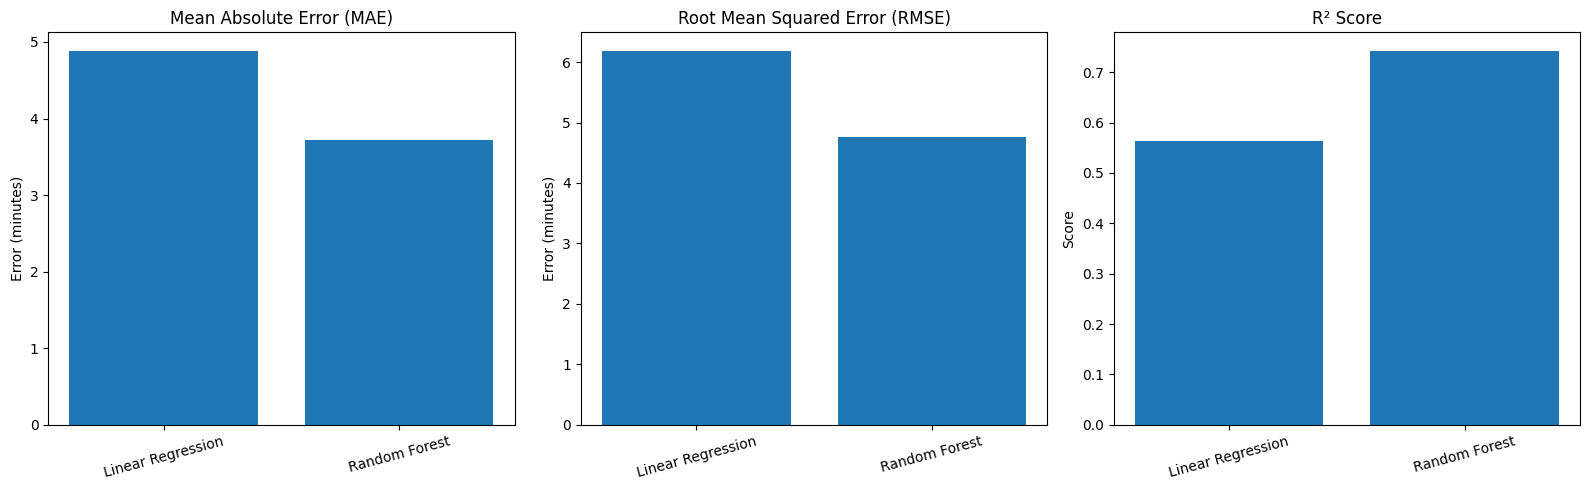

In [15]:

import matplotlib.pyplot as plt

# Prepare model comparison data
models = ["Linear Regression", "Random Forest"]

mae_values = [mae_linear, mae_rf]
rmse_values = [rmse_linear, rmse_rf]
r2_values = [r2_linear, r2_rf]

# Create evaluation metric plots
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].bar(models, mae_values)
axes[0].set_title("Mean Absolute Error (MAE)")
axes[0].set_ylabel("Error (minutes)")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(models, rmse_values)
axes[1].set_title("Root Mean Squared Error (RMSE)")
axes[1].set_ylabel("Error (minutes)")
axes[1].tick_params(axis="x", rotation=15)

axes[2].bar(models, r2_values)
axes[2].set_title("R² Score")
axes[2].set_ylabel("Score")
axes[2].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()



### **Analyze Feature Importance**

The feature importance scores from the Random Forest model are examined to identify the logistics factors that contribute most to delivery time predictions. The results help identify areas where operational improvements may reduce delivery delays.


Top 10 Important Features:
                           Feature  Importance
           Delivery_person_Ratings    0.205250
               multiple_deliveries    0.120769
         Road_traffic_density_Low     0.107234
               Delivery_person_Age    0.091301
                 Vehicle_condition    0.073953
Weatherconditions_conditions Sunny    0.056975
                 Time_Order_picked    0.039206
                       Time_Orderd    0.036690
                         Order_Day    0.034037
       Delivery_location_longitude    0.026856


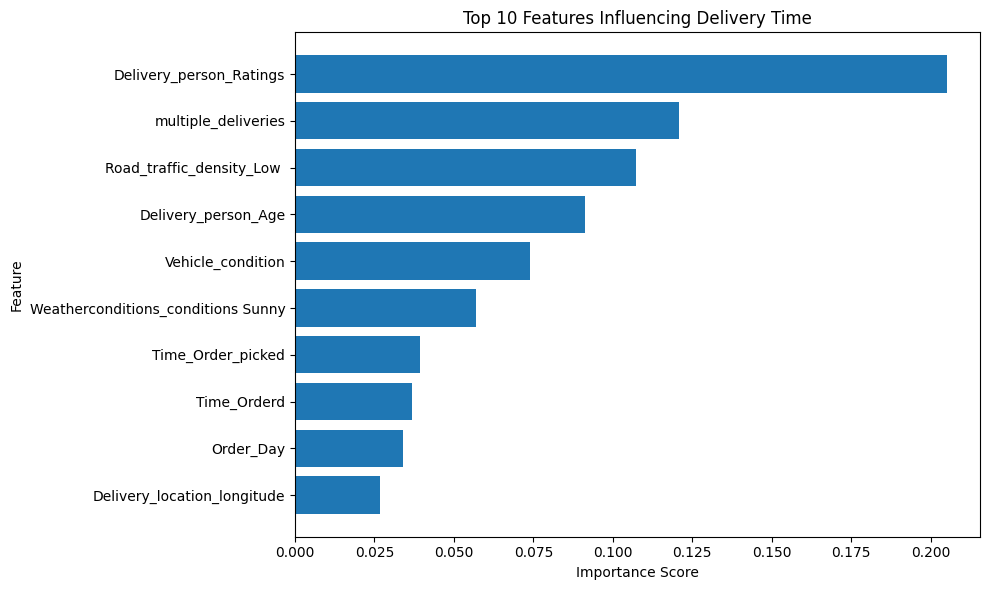

In [16]:

# Extract feature importance scores from the Random Forest model

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Visualize the top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Delivery Time")
plt.tight_layout()
plt.show()



### **Predict Delivery Time Using the Best Model**

The Random Forest model is used to predict delivery times for unseen test records. Actual and predicted delivery times are compared to assess the model's practical prediction accuracy.


Sample Actual vs Predicted Delivery Times:
 Actual Delivery Time (min)  Predicted Delivery Time (min)  Absolute Error (min)
                         44                          44.44                  0.44
                         41                          42.12                  1.12
                         39                          35.62                  3.38
                         38                          41.64                  3.64
                         38                          29.52                  8.48
                         22                          21.96                  0.04
                         14                          14.56                  0.56
                         17                          23.55                  6.55
                         22                          22.40                  0.40
                         29                          26.53                  2.47


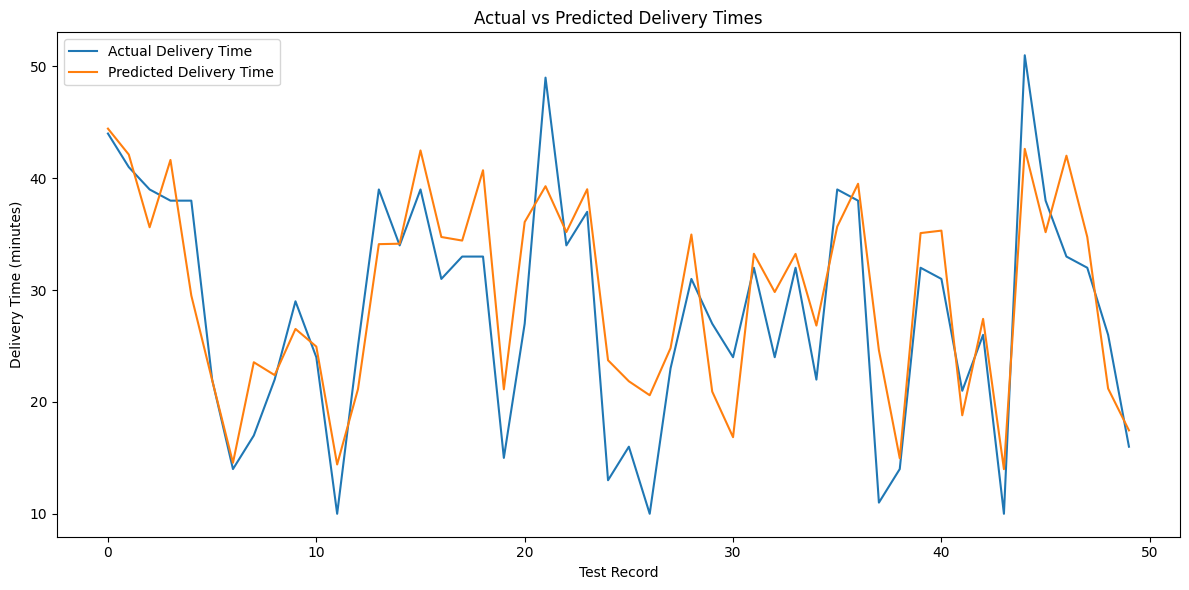

In [17]:

# Compare actual and predicted delivery times

prediction_comparison = pd.DataFrame({
    "Actual Delivery Time (min)": y_test.values,
    "Predicted Delivery Time (min)": np.round(y_pred_rf, 2)
})

prediction_comparison["Absolute Error (min)"] = np.abs(
    prediction_comparison["Actual Delivery Time (min)"]
    - prediction_comparison["Predicted Delivery Time (min)"]
)

print("Sample Actual vs Predicted Delivery Times:")
print(prediction_comparison.head(10).to_string(index=False))

# Visualize actual and predicted values for the first 50 test records
plt.figure(figsize=(12, 6))
plt.plot(
    prediction_comparison["Actual Delivery Time (min)"].head(50).values,
    label="Actual Delivery Time"
)
plt.plot(
    prediction_comparison["Predicted Delivery Time (min)"].head(50).values,
    label="Predicted Delivery Time"
)
plt.xlabel("Test Record")
plt.ylabel("Delivery Time (minutes)")
plt.title("Actual vs Predicted Delivery Times")
plt.legend()
plt.tight_layout()
plt.show()



### **Develop Logistics Optimization Strategies**

The model results and feature importance scores are used to identify opportunities for improving delivery operations. Strategies focus on delivery partner ratings, multiple deliveries, traffic conditions, vehicle maintenance, and delivery scheduling to reduce delays and improve efficiency.


In [18]:

# Define data-driven logistics optimization strategies

optimization_strategies = pd.DataFrame({
    "Factor": [
        "Delivery Partner Ratings",
        "Multiple Deliveries",
        "Road Traffic Density",
        "Vehicle Condition",
        "Weather Conditions",
        "Order and Pickup Timing"
    ],
    "Optimization Strategy": [
        "Provide delivery partner training and monitor service quality.",
        "Optimize delivery batching and limit excessive simultaneous orders.",
        "Use traffic-aware route planning and adjust dispatch times.",
        "Schedule regular vehicle inspections and maintenance.",
        "Adjust delivery time estimates and routes during adverse weather.",
        "Improve order preparation and pickup coordination."
    ]
})

print("Logistics Optimization Strategies")
print("---------------------------------")
print(optimization_strategies.to_string(index=False))


Logistics Optimization Strategies
---------------------------------
                  Factor                                               Optimization Strategy
Delivery Partner Ratings      Provide delivery partner training and monitor service quality.
     Multiple Deliveries Optimize delivery batching and limit excessive simultaneous orders.
    Road Traffic Density         Use traffic-aware route planning and adjust dispatch times.
       Vehicle Condition               Schedule regular vehicle inspections and maintenance.
      Weather Conditions   Adjust delivery time estimates and routes during adverse weather.
 Order and Pickup Timing                  Improve order preparation and pickup coordination.



### **Save the Trained Random Forest Model**

The trained Random Forest model is saved as a pickle file for future use. The saved model can be loaded later to predict delivery times without retraining the model.


In [19]:

import pickle

model_path = "/content/random_forest_delivery_model.pkl"

with open(model_path, "wb") as file:
    pickle.dump(rf_model, file)

print("Random Forest model saved successfully.")
print("Model file:", model_path)


Random Forest model saved successfully.
Model file: /content/random_forest_delivery_model.pkl



### **Verify the Saved Model**

The saved Random Forest model is loaded from the pickle file and tested on sample records to verify that it produces predictions consistent with the trained model.


In [20]:

# Load the saved model and verify its predictions

with open("/content/random_forest_delivery_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

sample_features = X_test.head(5)

loaded_predictions = loaded_model.predict(sample_features)
original_predictions = rf_model.predict(sample_features)

print("Saved model loaded successfully.")
print("\nSample predictions from the loaded model:")
print(np.round(loaded_predictions, 2))

print("\nMaximum difference from original model predictions:")
print(round(np.max(np.abs(loaded_predictions - original_predictions)), 10))

if np.allclose(loaded_predictions, original_predictions):
    print("\nVerification successful: predictions match.")
else:
    print("\nVerification failed: predictions do not match.")


Saved model loaded successfully.

Sample predictions from the loaded model:
[44.44 42.12 35.62 41.64 29.52]

Maximum difference from original model predictions:
0.0

Verification successful: predictions match.



### **Final Model Performance Summary**

The performance of Linear Regression and Random Forest models is summarized using MAE, MSE, RMSE, and R². The model with lower prediction errors and a higher R² score is selected as the preferred model for delivery time prediction.


In [21]:

# Summarize the final model evaluation results

final_model_summary = pd.DataFrame({
    "Metric": ["MAE (minutes)", "MSE", "RMSE (minutes)", "R² Score"],
    "Linear Regression": [
        mae_linear, mse_linear, rmse_linear, r2_linear
    ],
    "Random Forest": [
        mae_rf, mse_rf, rmse_rf, r2_rf
    ]
})

print("Final Model Performance Summary")
print("--------------------------------")
print(final_model_summary.round(4).to_string(index=False))

print("\nSelected Model:", best_model)
print(f"Random Forest average absolute prediction error: {mae_rf:.2f} minutes")
print(f"Random Forest R² score: {r2_rf:.4f}")


Final Model Performance Summary
--------------------------------
        Metric  Linear Regression  Random Forest
 MAE (minutes)             4.8815         3.7243
           MSE            38.2225        22.6101
RMSE (minutes)             6.1824         4.7550
      R² Score             0.5641         0.7421

Selected Model: Random Forest
Random Forest average absolute prediction error: 3.72 minutes
Random Forest R² score: 0.7421



### **Conclusion of Predictive Modeling and Optimization**

The Random Forest Regression model achieved an MAE of 3.72 minutes, an RMSE of 4.76 minutes, and an R² score of 0.7421, outperforming Linear Regression on the test dataset. Feature importance analysis identified delivery partner ratings, multiple deliveries, traffic conditions, and delivery partner age as influential prediction features. The proposed optimization strategies focus on route planning, delivery batching, vehicle maintenance, and pickup coordination. These findings demonstrate how predictive modeling can support delivery time estimation and logistics operational improvements.
